# Supplementary figure: marker genes of lung macrophage subtypes

Dot plots of macrophage subtype markers and of inflammation markers in the five macrophage populations of the lung single-cell data.
The dot colour shows the mean log1p-normalised expression (scaled to 0-1 per gene) and the dot size the fraction of expressing cells.
Subtypes are ordered by a dendrogram computed on their mean scANVI representation, as in Fig. 2a.
The summaries were extracted from the single-cell object in `00_prepare_tables_from_raw_data.ipynb`; the plot is equivalent to
`sc.pl.dotplot(macrophages, var_names, groupby, use_raw=True, log=True, standard_scale="var", dendrogram=True)` on the full data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
from anndata import AnnData

from figure_style import DOTPLOT_LEGEND_MM, DENSE_FONT_SIZE, add_dotplot_legends, figure_size, fit_dots_to_cells, save_panel, set_style, thin_scanpy_lines

set_style()
DATA = Path("../data")


def flatten_markers(marker_genes):
    """Genes in plotting order (DotPlot reads precomputed tables by column position, so columns must follow var_names)."""
    return [gene for genes in marker_genes.values() for gene in genes]



mean = pd.read_csv(DATA / "23_lung_macrophage_markers_mean_expression.csv", index_col=0)
fraction = pd.read_csv(DATA / "24_lung_macrophage_markers_fraction_expressing.csv", index_col=0)
representation = pd.read_csv(DATA / "lung_macrophages_scanvi_mean.csv", index_col=0).loc[mean.index]

# Scale mean expression to 0-1 per gene, as scanpy does with standard_scale="var"
scaled_mean = mean - mean.min(axis=0)
scaled_mean = (scaled_mean / scaled_mean.max(axis=0)).fillna(0)

# One "observation" per macrophage subtype; the plotted values come from the precomputed tables
macrophages = AnnData(
    X=scaled_mean.values,
    obs=pd.DataFrame({"cell_type": pd.Categorical(scaled_mean.index)}, index=scaled_mean.index.rename(None)),
    var=pd.DataFrame(index=scaled_mean.columns),
)
macrophages.obsm["X_rep"] = representation.values
sc.tl.dendrogram(macrophages, groupby="cell_type", use_rep="X_rep")


def macrophage_dotplot(marker_genes, name, width_mm):
    with plt.rc_context({"xtick.labelsize": DENSE_FONT_SIZE}):  # Gene names
        genes = flatten_markers(marker_genes)
        plot_width_mm = width_mm - DOTPLOT_LEGEND_MM
        dot_plot = sc.pl.DotPlot(
            macrophages, var_names=marker_genes, groupby="cell_type", dot_color_df=scaled_mean.loc[:, genes], dot_size_df=fraction.loc[:, genes],
            figsize=figure_size(plot_width_mm, 38),
        )
        dot_plot.add_dendrogram()
        dot_plot.style(cmap="Reds", dot_edge_lw=0.3, dot_max=1, dot_min=0, smallest_dot=0)
        dot_plot.legend(show=False)
        dot_plot.make_figure()
        fit_dots_to_cells(dot_plot)  # Size the dots from the laid-out axes so they never overflow their cells
        thin_scanpy_lines(dot_plot)
        add_dotplot_legends(dot_plot, colorbar_title="Mean expression\nin group (scaled)")
        save_panel(name)
        plt.show()

/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/tools/_dendrogram.py:135: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_df = rep_df.groupby(level=0).mean()


## Macrophage subtype markers

categories: Macrophages_Alveolar, Macrophages_Alveolar_APOE, Macrophages_Interstitial, etc.
var_group_labels: Common, Monocytic, PPARG, etc.


/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


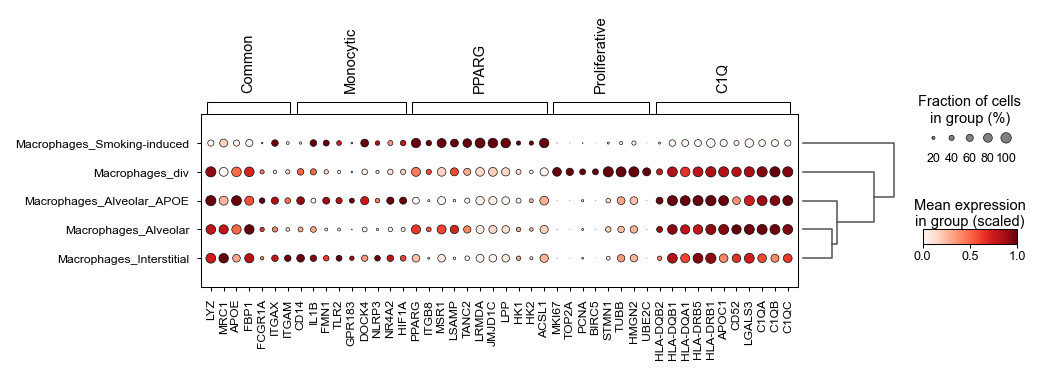

In [2]:
macrophages_markers = {
    "Common": ["LYZ", "MRC1", "APOE", "FBP1", "FCGR1A", "ITGAX", "ITGAM"],
    "Monocytic": ["CD14", "IL1B", "FMN1", "TLR2", "GPR183", "DOCK4", "NLRP3", "NR4A2", "HIF1A"],
    "PPARG": ["PPARG", "ITGB8", "MSR1", "LSAMP", "TANC2", "LRMDA", "JMJD1C", "LPP", "HK1", "HK2", "ACSL1"],
    "Proliferative": ["MKI67", "TOP2A", "PCNA", "BIRC5", "STMN1", "TUBB", "HMGN2", "UBE2C"],
    "C1Q": ["HLA-DQB2", "HLA-DQB1", "HLA-DQA1", "HLA-DRB5", "HLA-DRB1", "APOC1", "CD52", "LGALS3", "C1QA", "C1QB", "C1QC"],
}
macrophage_dotplot(macrophages_markers, name="Supp_Fig_lung_macrophage_markers", width_mm=183)

## Inflammation markers

categories: Macrophages_Alveolar, Macrophages_Alveolar_APOE, Macrophages_Interstitial, etc.
var_group_labels: Proinflammatory, Anti-inflammatory


/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


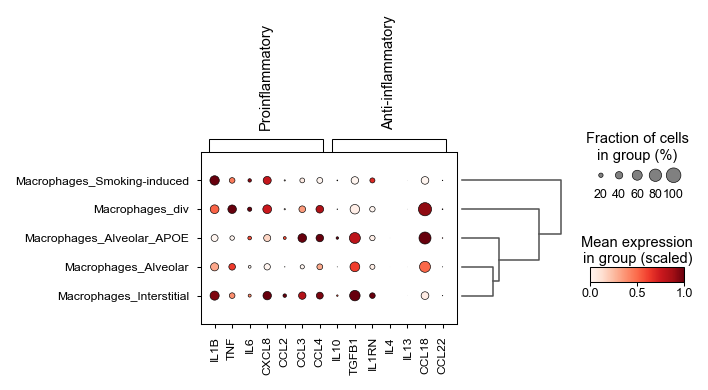

In [3]:
inflammation_markers = {
    "Proinflammatory": ["IL1B", "TNF", "IL6", "CXCL8", "CCL2", "CCL3", "CCL4"],
    "Anti-inflammatory": ["IL10", "TGFB1", "IL1RN", "IL4", "IL13", "CCL18", "CCL22"],
}
macrophage_dotplot(inflammation_markers, name="Supp_Fig_lung_macrophage_inflammation_markers", width_mm=110)